# 07 · Model Comparison

**Goal:** check that gradient boosting was the right choice for step 1 by comparing it with other model families, and see which clues the full system relies on.

Notebook 04 compared two models on step 1 alone. Here, every model is measured **end to end**: its probabilities go through the same step 2 (action model, cutoffs tuned on TRAIN at the 97% target), so any difference comes from the step-1 model.

| Model | What it is | Why it's here |
|---|---|---|
| Logistic regression | one weight per clue | the simple, readable baseline |
| Random forest | many deep trees on random samples, averaged | checks whether the gain is from boosting or just from trees |
| Neural network | a small multi-layer perceptron (`MLPClassifier`) | checks whether a neural model finds anything the trees miss |
| Gradient boosting (LightGBM) | many small trees, each fixing the last one's mistakes | the chosen model, with notebook 04's settings |
| Gradient boosting (scikit-learn) | the same method in `HistGradientBoostingClassifier` | checks that the result comes from the method, not the library |

Everything is tuned on TRAIN and compared on VAL. TEST and the holdout file aren't used.

**Questions**
1. Does another model family rank the right matter first more often, or give better probabilities?
2. Does that carry through to more entries decided with no person, and fewer silent errors?
3. Which groups of clues does the full system rely on?
4. Would more labeled entries help?

## 1. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

sys.path.insert(0, "../src")
from rules import answer_key, precision_ci, summarize
from classifier import two_step
from evaluate import pair_metrics

warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [2]:
RESULTS_DIR = Path("../results")
SEED = 210
TARGET = 0.97   # the default setting from notebook 04

LR_GRID = {"logisticregression__C": [0.01, 0.1, 1, 10]}
RF_GRID = {"min_samples_leaf": [20, 100], "max_features": ["sqrt", 0.5]}
RF_TREES = 200
MLP_GRID = {"mlpclassifier__hidden_layer_sizes": [(32,), (64, 32)], "mlpclassifier__alpha": [1e-4, 1e-2]}
MLP_EPOCHS = 50

# Step 2, same as notebook 04
ACTION_GB_GRID = {"n_estimators": [50, 100, 200], "num_leaves": [4, 7, 31], "min_child_samples": [20, 50, 100]}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2
CORRECT_TYPED_CMID = True
ROBUST_SHARE = 0.9

LC_SHARES = [0.25, 0.5, 0.75, 1.0]   # shares of TRAIN entries for the learning curve (section 7)
LC_REPEATS = 3                       # random draws per share below 1

SHOW = ["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "multi_caught",
        "shortlist_hit"]

## 2. Load data

Same pairs table and folds as notebook 04. The gradient boosting settings come from notebook 04's config, and the narrative text model from its saved models (it reads only the narrative, so it's the same for every step-1 model).

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
config_04 = json.loads((RESULTS_DIR / "04_config.json").read_text())
text_model = joblib.load(RESULTS_DIR / "04_model.joblib")["text_model"]
answers = answer_key(pairs)
narratives = pairs.drop_duplicates("entry_id").set_index("entry_id")["narrative_norm"]

feature_groups = feature_config["features"]
FEATURES = [col for cols in feature_groups.values() for col in cols]
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]
gb_params = config_04["model_params"]

train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
X_train, y_train = train_pairs[FEATURES], train_pairs["is_true_matter"]
cv = PredefinedSplit(train_pairs["fold"])

assert config_04["model"] == "gradient boosting"
assert "num_leaves" in gb_params, "rerun notebook 04 first (step 1 is now LightGBM)"
assert config_04["features"] == FEATURES
assert pairs[FEATURES].notna().all().all()
assert train_pairs.groupby("entry_id")["fold"].nunique().eq(1).all()
print(f"{len(FEATURES)} features | TRAIN: {train_pairs['entry_id'].nunique():,} entries | VAL: {val_pairs['entry_id'].nunique():,} entries")
print("Gradient boosting settings from notebook 04:", gb_params)

48 features | TRAIN: 2,802 entries | VAL: 601 entries
Gradient boosting settings from notebook 04: {'min_child_samples': 200, 'n_estimators': 400, 'num_leaves': 31}


## 3. Tune each model (TRAIN)

Each model is tuned on the 5 folds by log loss, like notebook 04.
- **Both gradient boosting versions keep notebook 04's settings,** so they're only cross-validated here. The names differ by library: `num_leaves` is `max_leaf_nodes`, `min_child_samples` is `min_samples_leaf`, and `n_estimators` is `max_iter`.
- **Logistic regression and the neural network get scaled clues** (`StandardScaler`), since both are sensitive to scale. Trees don't need it.
- **No early stopping for the neural network,** since it would split entries across a random slice of rows. It trains for a fixed number of passes, so scikit-learn may warn that it hasn't fully converged.
- **The random forest and neural network grids are the slow part** (several minutes each).

In [4]:
searches = {
    "logistic regression": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                                        LR_GRID, cv=cv, scoring="neg_log_loss", n_jobs=-1),
    "random forest": GridSearchCV(RandomForestClassifier(n_estimators=RF_TREES, n_jobs=-1, random_state=SEED),
                                  RF_GRID, cv=cv, scoring="neg_log_loss"),
    "neural network": GridSearchCV(make_pipeline(StandardScaler(), MLPClassifier(max_iter=MLP_EPOCHS, batch_size=1000,
                                                                                 early_stopping=False, random_state=SEED)),
                                   MLP_GRID, cv=cv, scoring="neg_log_loss", n_jobs=-1),
    "gradient boosting (scikit-learn)": GridSearchCV(
        HistGradientBoostingClassifier(learning_rate=0.05, early_stopping=False, random_state=SEED),
        {"max_leaf_nodes": [gb_params["num_leaves"]], "min_samples_leaf": [gb_params["min_child_samples"]],
         "max_iter": [gb_params["n_estimators"]]}, cv=cv, scoring="neg_log_loss"),
    "gradient boosting (LightGBM)": GridSearchCV(LGBMClassifier(learning_rate=0.05, random_state=SEED, verbose=-1),
                                                 {k: [v] for k, v in gb_params.items()}, cv=cv, scoring="neg_log_loss"),
}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: {search.best_params_} | log loss {-search.best_score_:.4f} | "
          f"{search.cv_results_['mean_fit_time'][search.best_index_]:.0f}s per fit")

logistic regression: {'logisticregression__C': 10} | log loss 0.0131 | 2s per fit
random forest: {'max_features': 'sqrt', 'min_samples_leaf': 20} | log loss 0.0130 | 7s per fit
neural network: {'mlpclassifier__alpha': 0.01, 'mlpclassifier__hidden_layer_sizes': (32,)} | log loss 0.0106 | 13s per fit
gradient boosting (scikit-learn): {'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 200} | log loss 0.0088 | 15s per fit
gradient boosting (LightGBM): {'min_child_samples': 200, 'n_estimators': 400, 'num_leaves': 31} | log loss 0.0087 | 4s per fit


## 4. Step 1 on its own (VAL)

Each model gets two sets of probabilities:
- **Cross-validated on TRAIN:** every TRAIN entry is scored by a model that never saw it. Step 2 trains on these.
- **VAL:** from the model refit on all of TRAIN.

`pair_metrics` (the same as notebook 05) gives the ranking and probability metrics, including the calibration error of each entry's top pick.

In [5]:
cv_probs, val_probs = {}, {}
for name, search in searches.items():
    cv_probs[name] = cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    val_probs[name] = search.best_estimator_.predict_proba(val_pairs[FEATURES])[:, 1]

step1 = pd.DataFrame({name: pair_metrics(val_pairs.assign(prob=p)) for name, p in val_probs.items()}).T
step1.insert(0, "train_cv_log_loss", [-s.best_score_ for s in searches.values()])
step1.drop(columns="entries").round(4)

,train_cv_log_loss,top_1,top_3,mrr,auroc,pr_auc,log_loss,calibration_error
logistic regression,0.0131,0.8848,0.9645,0.9272,0.9837,0.8506,0.0132,0.0998
random forest,0.0130,0.8972,0.9787,0.9385,0.9926,0.8895,0.0113,0.1412
neural network,0.0106,0.9184,0.9770,0.9480,0.9928,0.8977,0.0101,0.0889
gradient boosting (scikit-learn),0.0088,0.9362,0.9823,0.9600,0.9962,0.9197,0.0086,0.0528
gradient boosting (LightGBM),0.0087,0.9344,0.9894,0.9605,0.9963,0.9265,0.0081,0.0375


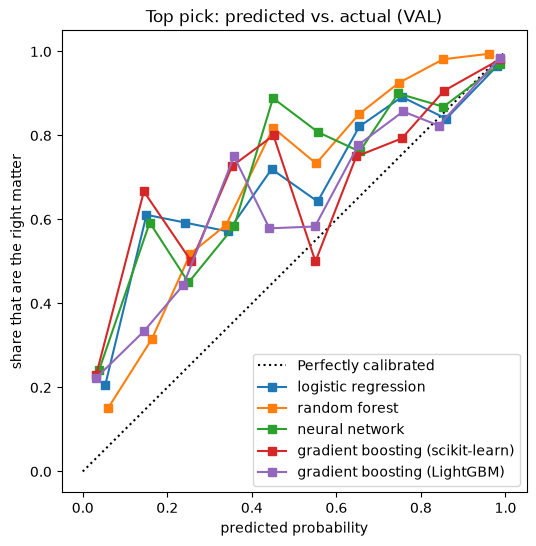

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in val_probs.items():
    df = val_pairs[["entry_id", "is_true_matter"]].assign(prob=p)
    top = df.loc[df.groupby("entry_id")["prob"].idxmax()]
    CalibrationDisplay.from_predictions(top["is_true_matter"], top["prob"], n_bins=10, name=name, ax=ax)
ax.set(title="Top pick: predicted vs. actual (VAL)", xlabel="predicted probability", ylabel="share that are the right matter")
plt.show()

- **Gradient boosting leads on every step-1 measure:** about 93.5% top-1, vs. 92% for the neural network, 90% for the random forest, and 88.5% for logistic regression.
- **The two libraries are about even** (93.6% vs. 93.4% top-1), so the gain comes from the method. LightGBM has the lower calibration error (0.038 vs. 0.053) and fits about 4 times faster (4 vs. 15 seconds).
- **AUROC barely separates the models** (0.984 to 0.996), since most wrong matters are easy for any model to rule out. Top-1, PR-AUC, and calibration show the real gaps.
- **The random forest has the worst calibration** (0.141), so its probabilities would make poor confidence scores.

## 5. End to end: the same step 2 for every model (VAL)

`two_step` (`src/classifier.py`) runs notebook 04's step 2 on top of any step-1 model: entry-level clues from that model's probabilities, the action model tuned on the same folds, `multi_min` by F2, and the other cutoffs at the 97% target with the same margin. With LightGBM it matches notebook 04's default setting.

With about 600 VAL entries, differences of 2 to 3 points in precision can be noise.

In [7]:
def run_step2(train_p, val_p, train=None):
    train = train_pairs if train is None else train
    return two_step(train, train_p, val_pairs, val_p, answers, narratives, text_model, CLIENT_COL, MATTER_COL, TARGET,
                    ACTION_GB_GRID, ACTION_GRID, MULTI_GRID, MULTI_BETA, CORRECT_TYPED_CMID, SEED, ROBUST_SHARE,
                    refit_text=train is not train_pairs)


def summary(scored):
    s = summarize(scored)
    s["ci_low"], s["ci_high"] = precision_ci(scored)
    return s


scored_val, cutoffs = {}, {}
for name in searches:
    scored_val[name], cutoffs[name], _ = run_step2(cv_probs[name], val_probs[name])

end_to_end = pd.DataFrame({name: summary(scored) for name, scored in scored_val.items()}).T[SHOW]
end_to_end.insert(0, "auto_min", [c["auto_min"] for c in cutoffs.values()])
end_to_end.round(3)

,auto_min,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,multi_caught,shortlist_hit
logistic regression,0.9,0.974,0.955,0.987,0.572,0.321,9.0,0.703,0.777
random forest,0.9,0.960,0.941,0.976,0.667,0.208,15.0,0.784,0.840
neural network,0.9,0.976,0.958,0.990,0.689,0.198,10.0,0.784,0.756
gradient boosting (scikit-learn),0.9,0.970,0.956,0.984,0.732,0.148,12.0,0.784,0.742
gradient boosting (LightGBM),0.9,0.977,0.964,0.989,0.735,0.151,9.0,0.811,0.791


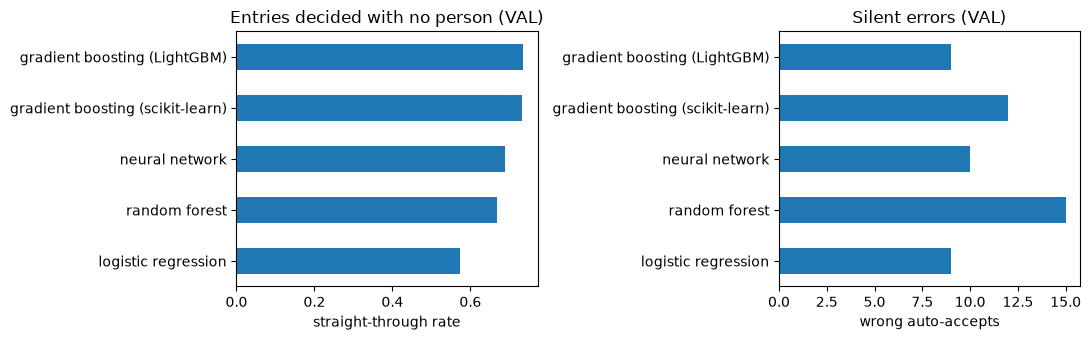

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
end_to_end["straight_through"].plot.barh(ax=axes[0], title="Entries decided with no person (VAL)")
end_to_end["silent_errors"].plot.barh(ax=axes[1], title="Silent errors (VAL)")
axes[0].set_xlabel("straight-through rate")
axes[1].set_xlabel("wrong auto-accepts")
plt.tight_layout()
plt.show()

- **The step-1 model mostly changes how much gets automated,** not how precise it is: from 57% decided with no person with logistic regression to 74% with LightGBM. Every model lands between 96% and 98% precision, since the cutoffs aim at the target.
- **Both gradient boosting versions decide the most** (73% to 74%) and send the fewest to review (15%).
- **LightGBM has fewer silent errors than scikit-learn's version** (9 vs. 12), but that gap is within the noise.
- **The random forest is the only model under the target** (96.0%), with the most silent errors (15).
- **The neural network is a close third** (69%) and doesn't find anything the trees miss.

## 6. Which clues does the full system rely on? (VAL)

Notebook 04 dropped each group of clues and measured step-1 top-1 on TRAIN. This goes further: LightGBM is retrained without each group, run through the same step 2, and scored on VAL. A drop in straight-through or a jump in silent errors means the system leans on that group.

- Step 2's own entry-level clues stay in, so this measures what each group adds through step 1.
- Cutoffs are re-picked each time, so changes of 2 to 3 points can be noise. Read the bigger moves.
- It retrains the full system once per group, so it takes a few minutes.

In [9]:
gb = searches["gradient boosting (LightGBM)"].best_estimator_

chosen = "gradient boosting (LightGBM)"
ablation = {"all clues": {"top_1": step1.loc[chosen, "top_1"], **summary(scored_val[chosen])}}
for group, cols in feature_groups.items():
    kept = [c for c in FEATURES if c not in cols]
    train_p = cross_val_predict(clone(gb), X_train[kept], y_train, cv=cv, method="predict_proba")[:, 1]
    val_p = clone(gb).fit(X_train[kept], y_train).predict_proba(val_pairs[kept])[:, 1]
    scored, _, _ = run_step2(train_p, val_p)
    ablation[f"without {group}"] = {"top_1": pair_metrics(val_pairs.assign(prob=val_p))["top_1"], **summary(scored)}

ablation = pd.DataFrame(ablation).T[["top_1"] + SHOW]
ablation.round(3)

,top_1,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,multi_caught,shortlist_hit
all clues,0.934,0.977,0.964,0.989,0.735,0.151,9.0,0.811,0.791
without typed_fields,0.931,0.977,0.963,0.988,0.724,0.148,7.0,0.838,0.820
without cmid,0.908,0.971,0.955,0.984,0.692,0.153,11.0,0.811,0.793
without names,0.933,0.971,0.959,0.982,0.747,0.136,11.0,0.811,0.841
without narrative,0.929,0.973,0.958,0.985,0.734,0.146,10.0,0.757,0.818
without dates,0.922,0.977,0.963,0.988,0.709,0.170,9.0,0.811,0.873
without history,0.933,0.976,0.961,0.988,0.687,0.176,7.0,0.811,0.868
without gaps,0.924,0.972,0.957,0.984,0.707,0.165,11.0,0.838,0.768
without past_narratives,0.924,0.980,0.966,0.990,0.732,0.160,9.0,0.811,0.781
without people,0.924,0.972,0.956,0.986,0.720,0.156,10.0,0.784,0.809


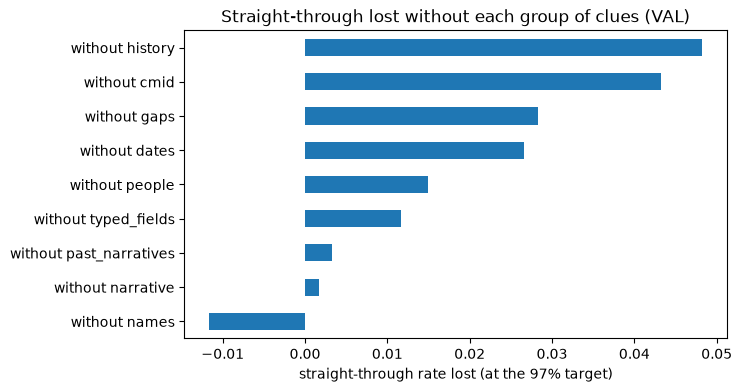

In [10]:
lost = ablation.loc["all clues", "straight_through"] - ablation["straight_through"].drop("all clues")
ax = lost.sort_values().plot.barh(figsize=(7, 4), title="Straight-through lost without each group of clues (VAL)")
ax.set_xlabel("straight-through rate lost (at the 97% target)")
plt.show()

- **Timekeeper history, CMID, gaps, and dates matter most:** without any one of them, 3 to 5 points fewer entries are decided with no person.
- **Without CMID or gaps, silent errors also rise** (11 vs. 9).
- **Typed names make the system more careful:** without them, slightly more is decided (74.7%), but with 2 more silent errors.
- **The narrative and people clues help catch multi-matter entries:** 76% and 78% are caught without them, vs. 81%.
- **Past narratives and the typed-field flags barely change the results here,** since other clues carry the same information on this data. They're kept for data where those other clues are missing.

## 7. Would more labeled entries help? (learning curve)

The full system is retrained on a random 25%, 50%, and 75% of TRAIN entries (`LC_REPEATS` draws each) and scored on VAL. A curve still rising at 100% means more labeled entries would help; a flat one means the models have learned what these clues can tell them.

- **Billing history stays the same** (built from all of TRAIN in notebook 02), so this measures labeled examples, not a firm with less history.
- Each draw retrains everything, so this takes a while.

In [11]:
train_ids = train_pairs.drop_duplicates("entry_id")["entry_id"]
curve = []
for share in LC_SHARES:
    for draw in range(LC_REPEATS if share < 1 else 1):
        ids = set(train_ids.sample(frac=share, random_state=SEED + draw))
        sub = train_pairs[train_pairs["entry_id"].isin(ids)].reset_index(drop=True)
        sub_cv = PredefinedSplit(sub["fold"])
        train_p = cross_val_predict(clone(gb), sub[FEATURES], sub["is_true_matter"], cv=sub_cv, method="predict_proba")[:, 1]
        val_p = clone(gb).fit(sub[FEATURES], sub["is_true_matter"]).predict_proba(val_pairs[FEATURES])[:, 1]
        scored, _, _ = run_step2(train_p, val_p, sub)
        curve.append({"share": share, "draw": draw, "train_entries": len(ids), **summary(scored),
                      "top_1": pair_metrics(val_pairs.assign(prob=val_p))["top_1"]})
curve = pd.DataFrame(curve)
curve_table = curve.groupby("share")[["train_entries", "top_1", "decided_precision", "straight_through", "silent_errors", "multi_caught"]].mean()
curve_table.round(3)

,train_entries,top_1,decided_precision,straight_through,silent_errors,multi_caught
share,,,,,,
0.25,700.0,0.918,0.988,0.432,2.333,0.874
0.50,1401.0,0.930,0.979,0.613,5.333,0.829
0.75,2102.0,0.933,0.976,0.669,7.000,0.838
1.00,2802.0,0.934,0.977,0.735,9.000,0.811


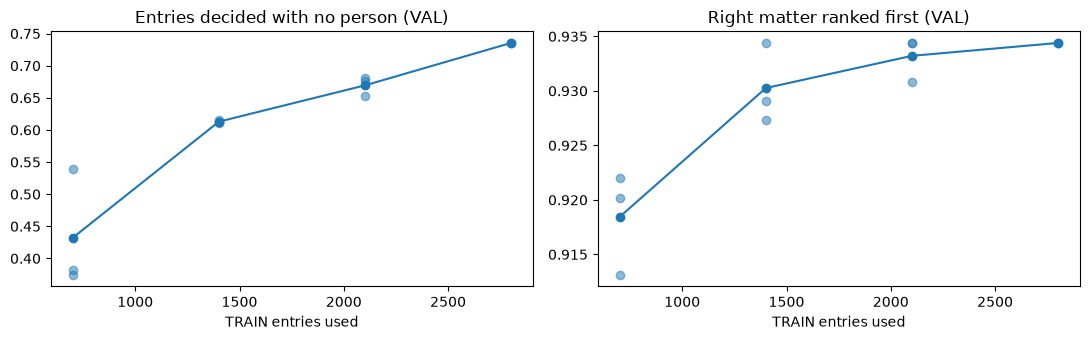

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col, title in [(axes[0], "straight_through", "Entries decided with no person (VAL)"), (axes[1], "top_1", "Right matter ranked first (VAL)")]:
    ax.scatter(curve["train_entries"], curve[col], alpha=0.5)
    ax.plot(curve.groupby("share")["train_entries"].mean(), curve.groupby("share")[col].mean(), marker="o")
    ax.set(title=title, xlabel="TRAIN entries used")
plt.tight_layout()
plt.show()

- **Top-1 levels off early:** 91.8% with a quarter of TRAIN and 93.4% with all of it, so step 1 has mostly learned what these clues can tell it.
- **The straight-through rate is still rising** (43% → 61% → 67% → 74%), so more labeled entries would mostly mean less review.
- **Precision stays at or above the target at every size.** With less data, the margin keeps the cutoffs cautious (98.8% with a quarter of TRAIN), so a smaller system decides less instead of making more mistakes.

## 8. Findings

### Results
- **Gradient boosting is the right family.** It has the best step-1 ranking and calibration, and decides the most entries with no person at the 97% target (74%, vs. 57% for logistic regression, 67% for the random forest, and 69% for the neural network).
- **The library doesn't change the accuracy.** LightGBM and scikit-learn are within the noise of each other, and LightGBM is faster and better calibrated.
- **The system relies most on timekeeper history, CMID, gaps, and dates.** Typed names make it more careful, and the narrative and people clues help catch multi-matter entries.
- **More labeled entries would mainly cut review:** top-1 is flat, but the straight-through rate is still rising.

### Tradeoffs
- **Simple vs. strong models:** logistic regression is easier to read but leaves about 17 more points of entries for review at the same precision. Reasons come from LightGBM's own contributions (notebook 04), so readability isn't lost by using it.
- **Keeping clues that look redundant:** some groups barely move VAL, but they cover each other when a field is missing, which real entries do more often.

### Limitations
- One VAL set of about 600 entries, so gaps of 2 to 3 points or a few silent errors can be noise.
- The ablation drops whole groups with step 1's settings fixed.
- The learning curve keeps billing history fixed.
- Everything is synthetic, so the gaps between models may differ on real entries.

### Next steps
- Keep LightGBM for both steps.
- Retrain as a firm's confirmed entries grow (`src/train.py`) and track the straight-through rate, which should keep rising.